# Лабораторная работа: классификация ЭКГ. Часть 2 — классификатор

В этой части вы обучите нейросетевой классификатор диагнозов на датасете, который собрали и экспортировали в первой части (`ecg-warehouse/notebooks/lab_dataset.ipynb`), оцените его на тестовой выборке и попробуете улучшить базовую модель.

Обучение построено на PyTorch Lightning и библиотеке `ecg_ml`: `WarehouseDatasetModule` загружает экспорт `ecg-warehouse`, `ClassifierLModule` реализует шаги обучения, валидации и теста.

Задача **многометочная** (multi-label): классы не взаимоисключающие, у одной записи может быть несколько кодов варианта сразу (например, `IMI` и `ASMI`) или ни одного. Поэтому у сети по одному независимому выходу на класс, а не softmax по классам.

Ноутбук выполняется в окружении проекта `ecg-ml`: установите его командой `uv sync` в корне репозитория и выберите ядро из `.venv`.

In [1]:
import os
from pathlib import Path

# Пути в ноутбуке отсчитываются от корня репозитория, а Jupyter может запустить ноутбук из notebooks/.
if Path.cwd().name == "notebooks":
    os.chdir("..")

### Настройки

Номер варианта совпадает с первой частью. Разбиение train/val и инициализация фиксируются значением `SEED`. Сначала обучается свёрточная сеть с обычной BCE, затем та же сеть с поправкой на частоту меток. Обе модели получают одинаковое число эпох.

In [2]:
VARIANT = 1
DATASET_PATH = f"data/ptb-xl-variant-{VARIANT}"

SEED = 42
LEARNING_RATE = 0.001
BATCH_SIZE = 64
NUM_WORKERS = 0
EPOCHS = 15


In [3]:
from copy import deepcopy
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from lightning import Callback, Trainer, seed_everything
from lightning.pytorch.loggers import CSVLogger
from torch import nn

from ecg_ml.data.warehouse import WarehouseDatasetModule
from ecg_ml.modules.classifier import ClassifierLModule

torch.set_num_threads(4)


W1111 23:15:29.648000 11736 torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


## 1. Данные

`WarehouseDatasetModule` читает `signals.npz` и `meta.csv` из экспорта. Тестовая выборка — часть `test` из разбиения хранилища. Валидационная выделяется из `train` тоже по пациентам, около 10 % пациентов; `random_state` фиксирует это разбиение, чтобы модели сравнивались на одних и тех же записях.

Классы и их порядок берутся из экспорта: `CLASSES` совпадёт со списком из первой части.

In [4]:
dataset = WarehouseDatasetModule(DATASET_PATH, random_state=SEED)
datamodule = dataset.to_datamodule(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)

CLASSES = dataset.classes
CLASSES
assert np.isfinite(dataset.pos_weight).all()
assert dataset.X_train.shape[1:] == (12, 5000)
display(pd.DataFrame({
    "train": dataset.Y_train.sum(axis=0),
    "val": dataset.Y_val.sum(axis=0),
    "test": dataset.Y_test.sum(axis=0),
    "pos_weight": dataset.pos_weight,
}, index=CLASSES).round(3))


,train,val,test,pos_weight
NORM,6837,766,1911,0.151
AFIB,1062,117,335,6.411


## 2. Архитектура

Одномерные свёртки обучаются выделять локальные паттерны ЭКГ. Первая свёртка объединяет информацию 12 отведений, последующие блоки увеличивают временной контекст. Усреднение по нескольким временным участкам сохраняет грубую последовательность событий, глобальный максимум выделяет выраженные локальные события. На выходе по одному логиту на метку. Несколько кодов могут присутствовать у одной записи, поэтому использую BCE и независимые sigmoid.

In [5]:
class ECGClassifier(nn.Module):
    def __init__(self, output_size):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv1d(12, 24, kernel_size=21, stride=5, padding=10, bias=False),
            nn.BatchNorm1d(24),
            nn.GELU(),
            nn.MaxPool1d(2),
            nn.Conv1d(24, 48, kernel_size=11, stride=2, padding=5, bias=False),
            nn.BatchNorm1d(48),
            nn.GELU(),
            nn.Conv1d(48, 64, kernel_size=9, stride=2, padding=4, bias=False),
            nn.BatchNorm1d(64),
            nn.GELU(),
            nn.Conv1d(64, 96, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm1d(96),
            nn.GELU(),
        )
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(96 * 6, output_size))

    def forward(self, x):
        features = self.encoder(x)
        averages = [part.mean(dim=-1) for part in features.tensor_split(5, dim=-1)]
        pooled = torch.cat([*averages, features.amax(dim=-1)], dim=1)
        return self.head(pooled)


example = ECGClassifier(len(CLASSES)).eval()
with torch.inference_mode():
    assert example(torch.zeros(2, 12, 5000)).shape == (2, len(CLASSES))
print(f"Обучаемых параметров: {sum(p.numel() for p in example.parameters()):,}")


Обучаемых параметров: 90,994


## 3. Обучение и выбор эпохи

Использую Adam и `ReduceLROnPlateau`. Для каждого запуска сохраняю веса эпохи с наибольшим macro-F1 на валидации. Взвешенная BCE использует отношение отрицательных примеров к положительным отдельно для каждой метки, рассчитанное только на train. Сравнение проводится с одним порогом вероятности 0,5.

In [6]:
class BestValidation(Callback):
    def __init__(self):
        self.score = -1.0
        self.epoch = None
        self.weights = None

    def on_validation_end(self, trainer, model):
        if trainer.sanity_checking:
            return
        score = float(trainer.callback_metrics["val/f1/macro"])
        if score > self.score:
            self.score = score
            self.epoch = trainer.current_epoch + 1
            self.weights = deepcopy(model.network.state_dict())


def train_classifier(name, pos_weight=None):
    seed_everything(SEED, workers=True)
    best = BestValidation()
    model = ClassifierLModule(
        optimizer=partial(torch.optim.Adam, lr=LEARNING_RATE),
        lr_scheduler={
            "scheduler": partial(torch.optim.lr_scheduler.ReduceLROnPlateau,
                                 mode="min", factor=0.5, patience=3),
            "monitor": "val/loss",
        },
        criterion=nn.BCEWithLogitsLoss(pos_weight=pos_weight),
        network=ECGClassifier(output_size=len(CLASSES)),
        labels=CLASSES,
    )
    logger = CSVLogger("logs/lab", name=name)
    trainer = Trainer(
        accelerator="auto",
        devices=1,
        max_epochs=EPOCHS,
        deterministic=True,
        logger=logger,
        callbacks=[best],
        enable_checkpointing=False,
        enable_progress_bar=False,
        enable_model_summary=False,
    )
    trainer.fit(model, datamodule=datamodule)
    model.network.load_state_dict(best.weights)
    history = pd.read_csv(Path(logger.log_dir) / "metrics.csv")
    return trainer, model, best, history


In [7]:
runs = {
    "Обычная BCE": train_classifier("baseline"),
    "Взвешенная BCE": train_classifier(
        "weighted", torch.as_tensor(dataset.pos_weight, dtype=torch.float32)
    ),
}
validation = pd.DataFrame({
    name: {"Лучшая эпоха": best.epoch, "Val macro-F1": best.score}
    for name, (_, _, best, _) in runs.items()
}).T
selected_model = validation["Val macro-F1"].idxmax()
display(validation.round(4))
print(f"По валидации выбрана модель: {selected_model}.")


Seed set to 42


.\ecg-ml\data\deps\lightning\pytorch\utilities\parsing.py:213: Attribute 'criterion' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['criterion'])`.
.\ecg-ml\data\deps\lightning\pytorch\utilities\parsing.py:213: Attribute 'network' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['network'])`.


GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


... (8 outputs left out)

.\ecg-ml\data\deps\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
.\ecg-ml\data\deps\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.
.\ecg-ml\data\deps\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


`Trainer.fit` stopped: `max_epochs=15` reached.


,Лучшая эпоха,Val macro-F1
Обычная BCE,14.0,0.9920
Взвешенная BCE,14.0,0.9923


По валидации выбрана модель: Взвешенная BCE.


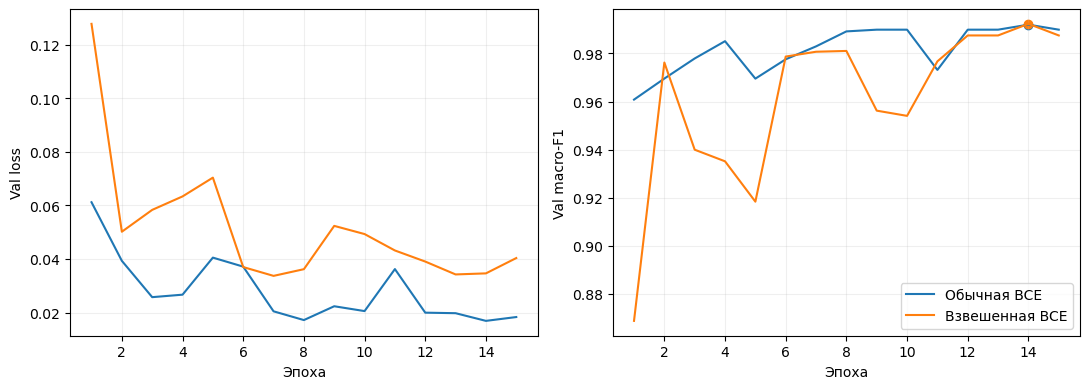

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, (_, _, best, history) in runs.items():
    for ax, metric, label in zip(
        axes, ["val/loss", "val/f1/macro"], ["Val loss", "Val macro-F1"]
    ):
        points = history.dropna(subset=[metric])
        ax.plot(points["epoch"] + 1, points[metric], label=name)
        ax.set(xlabel="Эпоха", ylabel=label)
        ax.grid(alpha=0.2)
    axes[1].scatter(best.epoch, best.score)
axes[1].legend()
fig.tight_layout()
plt.show()


## 4. Тестовая выборка

После выбора эпох и модели по валидации сравниваю обе конфигурации на отложенных пациентах. Precision, recall и F1 считаются отдельно для каждой метки. Macro-F1 усредняет F1 по классам с одинаковым весом.

In [9]:
test_results = {}
for name, (trainer, model, _, _) in runs.items():
    print(name)
    test_results[name], = trainer.test(model, datamodule=datamodule, verbose=False)

test = pd.DataFrame(test_results).T
comparison = validation.join(test[["test/f1/macro", "test/precision/macro", "test/recall/macro"]])
display(comparison.round(4))


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Обычная BCE


.\ecg-ml\data\deps\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
.\ecg-ml\data\deps\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


              precision    recall  f1-score   support

        NORM       1.00      1.00      1.00      1911
        AFIB       0.98      0.97      0.97       335

   micro avg       0.99      0.99      0.99      2246
   macro avg       0.99      0.98      0.98      2246
weighted avg       0.99      0.99      0.99      2246
 samples avg       0.99      0.99      0.99      2246

Взвешенная BCE


.\ecg-ml\data\deps\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
.\ecg-ml\data\deps\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


              precision    recall  f1-score   support

        NORM       1.00      0.99      0.99      1911
        AFIB       0.95      0.97      0.96       335

   micro avg       0.99      0.99      0.99      2246
   macro avg       0.97      0.98      0.98      2246
weighted avg       0.99      0.99      0.99      2246
 samples avg       0.99      0.99      0.99      2246



,Лучшая эпоха,Val macro-F1,test/f1/macro,test/precision/macro,test/recall/macro
Обычная BCE,14.0,0.9920,0.9835,0.9856,0.9815
Взвешенная BCE,14.0,0.9923,0.9771,0.9744,0.9799


In [10]:
metrics = test_results[selected_model]
per_class = pd.DataFrame([
    {"Модель": name, "Метка": code, **{
        metric: values[f"test/{metric}/{code}"]
        for metric in ("precision", "recall", "f1")
    }}
    for name, values in test_results.items()
    for code in CLASSES
]).set_index(["Модель", "Метка"])
display(per_class.round(4))

print(f"Выбранная по валидации модель: {selected_model}.")
print(f"Её macro-F1 на тесте: {metrics['test/f1/macro']:.4f}.")
delta = test.loc["Взвешенная BCE", "test/f1/macro"] - test.loc["Обычная BCE", "test/f1/macro"]
print(f"Разница macro-F1 на тесте (взвешенная − обычная BCE): {delta:+.4f}.")

afib = per_class.xs("AFIB", level="Метка")
precision_delta = afib.loc["Взвешенная BCE", "precision"] - afib.loc["Обычная BCE", "precision"]
recall_delta = afib.loc["Взвешенная BCE", "recall"] - afib.loc["Обычная BCE", "recall"]
print(f"Для редкой метки AFIB взвешивание изменило precision на {precision_delta:+.4f}, "
      f"recall на {recall_delta:+.4f}.")


precision  recall      f1
Модель         Метка                           
Обычная BCE    NORM      0.9953  0.9958  0.9956
               AFIB      0.9759  0.9672  0.9715
Взвешенная BCE NORM      0.9958  0.9927  0.9942
               AFIB      0.9529  0.9672  0.9600

Выбранная по валидации модель: Взвешенная BCE.
Её macro-F1 на тесте: 0.9771.
Разница macro-F1 на тесте (взвешенная − обычная BCE): -0.0064.
Для редкой метки AFIB взвешивание изменило precision на -0.0230, recall на +0.0000.


## Вывод

На валидации взвешенная BCE получила macro-F1 0,9923, обычная BCE — 0,9920. По этому критерию выбрана взвешенная модель. На 2 240 тестовых ЭКГ она получила macro-F1 0,9771, а обычная модель — 0,9835.

Взвешивание сохранило полноту для AFIB на уровне 0,9672, но снизило точность с 0,9759 до 0,9529. На данном разбиении попытка компенсировать дисбаланс дала небольшое преимущество на валидации и ухудшила результат на тесте. Оценка проведена на пациентах, которые не участвовали в обучении и выборе эпохи.